In [107]:
import numpy as np
from matplotlib import pyplot as plt

In [108]:
#Class for induvigual neuron, will expand into a layer
class Linear:
    def __init__(self, bias=np.inf, weight=np.inf,learning_rate = 0.001):
        self.x = None
        self.learning_rate = learning_rate
        self.bias = bias if bias != np.inf else np.random.uniform(-1,1,size=[1])[0]
        self.weight = weight if weight != np.inf else np.random.uniform(-1,1,size=[1])[0]
    def __init__(self, learning_rate = 0.001):
        self.x = None
        self.learning_rate = learning_rate
        self.bias = np.random.uniform(-1,1,size=[1])[0]
        self.weight = np.random.uniform(-1,1,size=[1])[0]
    def forward_pass(self,x):
        self.x = x
        return self.weight*x + self.bias
    def backward_pass(self, derivative):
        return derivative * self.weight
    def update(self, derivative):
        self.weight -= self.learning_rate*np.average(self.x * derivative)
        self.bias -= self.learning_rate * derivative
        self.x = np.array([])

In [109]:
#Class for induvigual neuron (Relu)
class Relu:
    def __init__(self):
        return
    def forward_pass(self,x):
        self.x = np.where(x > 0,x,0)
        return self.x
    def backward_pass(self, derivative):
        return derivative * self.x
    def update(self, derivative):
        return

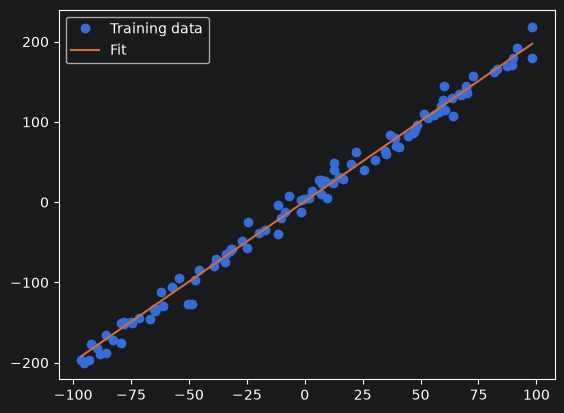

In [110]:
#Creating inputs:
w,b = 2,1
scale = 100
deviation = 0.1
x = np.random.uniform(-scale,scale,size=[scale])
x.sort()
y = x * w + b + np.random.normal(0,scale*deviation,size=[scale])

plt.plot(x,y,'o',label="Training data")
plt.plot(np.array([np.min(x),np.max(x)]),np.array([np.min(x),np.max(x)])*w+b,label="Fit")
plt.legend()
plt.show()

In [111]:
#Creating layers
learning_rate = 0.001
input = Linear(learning_rate)
output = Linear(learning_rate)
model = [input,output]
print(f"input weight: {input.weight}, input bias: {input.bias},\noutput weight: {output.weight}, output bias: {output.bias}")

input weight: 0.7013264139563724, input bias: -0.21622733039206854,
output weight: -0.2065592509906229, output bias: -0.7803346709878394


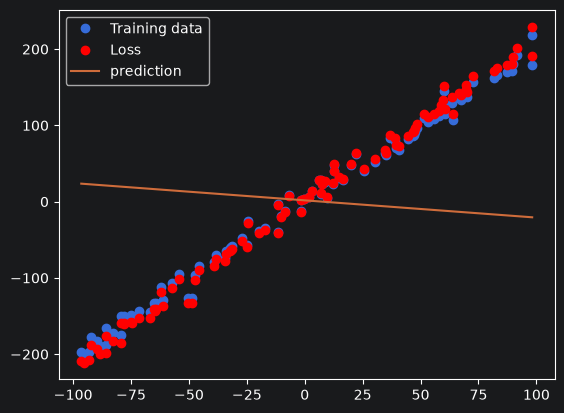

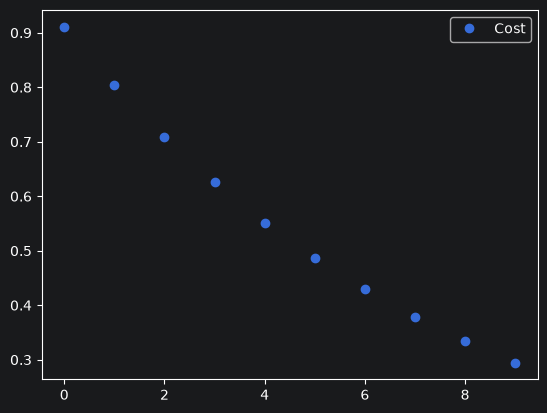

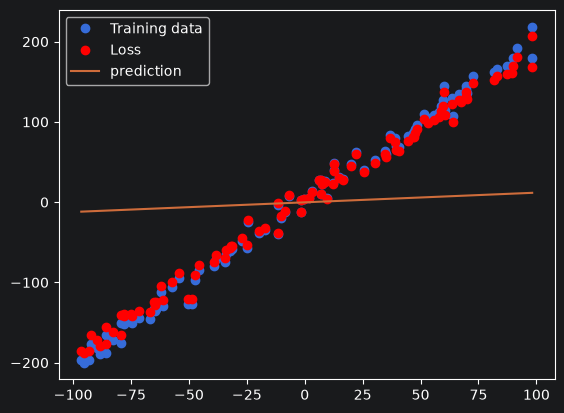

In [119]:
#Simulating forwards pass:

#Creating layers
learning_rate = 0.1
input = Linear(learning_rate)
activation = Relu()
output = Linear(learning_rate)
model = [input]

temp = x
for i in model:
    temp = i.forward_pass(temp)

plt.plot(x,y,'o',label="Training data")
plt.plot(x,y-temp,'o',label="Loss",color="red")
plt.plot(np.array([x[0],x[-1]]),np.array([temp[0],temp[-1]])*w+b,label="prediction")
plt.legend()
plt.show()

cost_history = []
for i in range(10):
    temp = np.average(temp-y)
    cost_history.append(temp)
    for j in reversed(model):
        temp2 = j.backward_pass(temp)
        j.update(temp)
        temp = temp2

    temp = x
    for i in model:
        temp = i.forward_pass(temp)

plt.plot(cost_history,'o',label="Cost")
plt.legend()
plt.show()

plt.plot(x,y,'o',label="Training data")
plt.plot(x,y-temp,'o',label="Loss",color="red")
plt.plot(x,temp,label="prediction")
plt.legend()
plt.show()